# Notebook 05 · Annexe de Maths : la régression logistique, à la main

Support de calcul de l'annexe du cours *Mathematics & Statistics for Machine Learning*. Elle doit dériver la loss, le gradient et le prior de régularisation du modèle, puis analyser la sensibilité de son optimisation aux hyperparamètres. Le plan suit la recette de L1 : données, modèle, coût, optimiseur, évaluation.

| Section | Contenu | Cours |
|---|---|---|
| 1 | Données et modèle | L1, L2, S2 |
| 2 | Coût : maximum de vraisemblance → log-loss | antisèche proba/stats, S2, L5 |
| 3 | Gradient, et vérification numérique | L1, L3 |
| 4 | Régularisation L2 = prior gaussien | S3, L7 |
| 5 | Descente de gradient codée à la main, comparée à scikit-learn | L1 |
| 6 | Sensibilité : pas α et borne de convergence, itérations, λ, point de départ | L1, L8 |
| 7 | Option L2 : moindres carrés et R² | L2 |

**Données.** Exactement celles du modèle final : les 143 mois d'entraînement, passés par la préparation de la pipeline (imputation, distances aux régimes k-means, standardisation), soit d = 12 variables. Pour coller au modèle final, **y = 1 si le Nikkei baisse** le mois suivant. Avec y = 1 si hausse, tous les poids changent de signe et rien d'autre ne change.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "config.yaml"))
FIG, RUNS = ROOT / "figures", ROOT / "runs"
SEED = CFG["seed"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

table = pd.read_csv(ROOT / CFG["data"]["model_table"], parse_dates=["date"]).set_index("date")
FEATURES = [c for g in ["news", "price", "macro", "fx"] for c in CFG["features"][g]]
COLONNES = FEATURES + [c for c in CFG["features"]["regime"] if c not in FEATURES]
train, valid = table[table["bloc"] == "entraînement"], table[table["bloc"] == "validation"]

PIPE = joblib.load(RUNS / "models" / "nikkei_logit.joblib")
PREP = PIPE[:-1]                                   # imputation + k-means + standardisation, ajustés sur l'entraînement
X, Xv = PREP.transform(train[COLONNES]), PREP.transform(valid[COLONNES])
y, yv = train["y_baisse"].to_numpy(), valid["y_baisse"].to_numpy()
m, d = X.shape
C_FINAL = PIPE.named_steps["model"].C
LAM = 1 / (2 * m * C_FINAL)
print(f"m = {m} mois, d = {d} variables standardisées | C du modèle final = {C_FINAL:.4f} -> λ = 1/(2mC) = {LAM:.4f}")

m = 143 mois, d = 12 variables standardisées | C du modèle final = 0.0299 -> λ = 1/(2mC) = 0.1168


## 1. Le modèle (S2, L3)

$$p^{(i)}=f_{w,b}\big(x^{(i)}\big)=\sigma\big(w^\top x^{(i)}+b\big),\qquad \sigma(u)=\frac{1}{1+e^{-u}},\qquad \sigma'(u)=\sigma(u)\big(1-\sigma(u)\big)$$

La dérivée de la sigmoïde s'obtient en dérivant (1 + e<sup>−u</sup>)<sup>−1</sup> : σ'(u) = e<sup>−u</sup>/(1 + e<sup>−u</sup>)<sup>2</sup> = σ(u)·(1 − σ(u)). C'est elle qui rend le gradient si simple à la section 3.

## 2. Le coût, par maximum de vraisemblance

Chaque mois est un tirage de Bernoulli de paramètre p<sup>(i)</sup>. Si les mois sont supposés indépendants, la vraisemblance est un produit. On prend son logarithme, on le change de signe et on le divise par m : on obtient la log-loss.

$$L(w,b)=\prod_{i=1}^{m}\big(p^{(i)}\big)^{y^{(i)}}\big(1-p^{(i)}\big)^{1-y^{(i)}},\qquad J(w,b)=-\frac{1}{m}\log L(w,b)=-\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log p^{(i)}+\big(1-y^{(i)}\big)\log\big(1-p^{(i)}\big)\Big]$$

*Limite de l'hypothèse.* Les rendements mensuels successifs sont peu corrélés, mais pas exactement indépendants : la vraisemblance est une approximation. C'est un point de discussion pour l'oral.

In [2]:
def sigmoide(u):
    return 1 / (1 + np.exp(-u))

def cout(w, b, X, y, lam=0.0):
    p = np.clip(sigmoide(X @ w + b), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)) + lam * (w @ w)

def gradient(w, b, X, y, lam=0.0):
    r = sigmoide(X @ w + b) - y
    return X.T @ r / len(y) + 2 * lam * w, r.mean()

## 3. Le gradient, par la règle de la chaîne (L1, L3)

Pour un mois, avec u = w<sup>⊤</sup>x + b :

$$\frac{\partial J_i}{\partial w_j}=\underbrace{\left(-\frac{y}{p}+\frac{1-y}{1-p}\right)}_{\partial J_i/\partial p}\cdot\underbrace{p(1-p)}_{\partial p/\partial u}\cdot\underbrace{x_j}_{\partial u/\partial w_j}=(p-y)\,x_j
\qquad\Rightarrow\qquad
\nabla_w J=\frac{1}{m}X^\top(p-y),\qquad \frac{\partial J}{\partial b}=\frac{1}{m}\sum_{i=1}^{m}\big(p^{(i)}-y^{(i)}\big)$$

C'est la même forme que pour la régression linéaire de L1 : l'erreur de prédiction multipliée par l'entrée.

**Vérification numérique.** On compare le gradient analytique à des différences finies centrées, (J(w + εe<sub>j</sub>) − J(w − εe<sub>j</sub>))/2ε, en un point tiré au hasard.

In [3]:
rng = np.random.default_rng(SEED)
w0, b0, eps = rng.normal(size=d), 0.3, 1e-6
gw, gb = gradient(w0, b0, X, y, LAM)
num = np.array([(cout(w0 + eps * e, b0, X, y, LAM) - cout(w0 - eps * e, b0, X, y, LAM)) / (2 * eps) for e in np.eye(d)])
num_b = (cout(w0, b0 + eps, X, y, LAM) - cout(w0, b0 - eps, X, y, LAM)) / (2 * eps)
erreur = np.abs(np.r_[gw, gb] - np.r_[num, num_b]).max() / np.abs(np.r_[gw, gb]).max()
print(f"écart relatif maximal entre gradient analytique et différences finies : {erreur:.1e}")
assert erreur < 1e-6

écart relatif maximal entre gradient analytique et différences finies : 1.3e-09


## 4. La régularisation L2 comme prior gaussien (S3, L7)

On suppose a priori que chaque poids suit une loi normale centrée : w ~ 𝒩(0, τ²I). Maximiser la probabilité a posteriori (MAP) revient à ajouter −log p(w), divisé par m, au coût :

$$-\frac{1}{m}\log p(w)=\frac{\lVert w\rVert_2^2}{2m\tau^2}+\text{cste}\;\Rightarrow\;J_\lambda(w,b)=J(w,b)+\lambda\lVert w\rVert_2^2,\qquad \lambda=\frac{1}{2m\tau^2},\qquad \nabla_w J_\lambda=\frac{1}{m}X^\top(p-y)+2\lambda w$$

- L'intercept *b* n'a pas de prior : il n'est pas pénalisé. C'est pourquoi la pipeline utilise le solveur `saga`, alors que `liblinear` pénalise aussi *b* (notebook 02).
- scikit-learn minimise ½‖w‖² + C·Σ ℓ<sub>i</sub>. En divisant par C·m, on retrouve J<sub>λ</sub> avec λ = 1/(2mC).
- J<sub>λ</sub> est **strictement convexe** dès que λ > 0. Sa hessienne, (1/m)·X̃<sup>⊤</sup>SX̃ + 2λ·diag(1, …, 1, 0), avec S = diag(p(1 − p)) et X̃ = [X, 1], est définie positive. Le minimum est donc unique.

In [4]:
tau = np.sqrt(1 / (2 * m * LAM))
print(f"λ = {LAM:.4f}  <=>  écart-type a priori de chaque poids τ = {tau:.3f}")
print("lecture : avant de voir les données, on juge qu'un écart-type de plus sur une variable change le log-odds de la baisse "
      f"de moins de {2 * tau:.2f} environ (deux τ), dans 95 % des cas")

λ = 0.1168  <=>  écart-type a priori de chaque poids τ = 0.173
lecture : avant de voir les données, on juge qu'un écart-type de plus sur une variable change le log-odds de la baisse de moins de 0.35 environ (deux τ), dans 95 % des cas


## 5. L'optimiseur : la descente de gradient (L1)

$$w\leftarrow w-\alpha\,\nabla_w J_\lambda(w,b),\qquad b\leftarrow b-\alpha\,\frac{\partial J_\lambda}{\partial b},\qquad \text{départ } w=0,\ b=0$$

**Le pas.** Le gradient de J<sub>λ</sub> est L-lipschitzien, avec L ≤ ¼·λ<sub>max</sub>(X̃<sup>⊤</sup>X̃/m) + 2λ, puisque p(1 − p) ≤ ¼. Le pas classique est α = 1/L, et la descente converge pour tout α < 2/L. Cette borne va un peu au-delà de L1 : c'est le sujet de L8, pas encore donné.

In [5]:
Xt = np.c_[X, np.ones(m)]
L_BORNE = 0.25 * np.linalg.eigvalsh(Xt.T @ Xt / m).max() + 2 * LAM
ALPHA = 1 / L_BORNE

def descente(X, y, alpha, lam, T, w=None, b=0.0, suivi=None):
    w = np.zeros(X.shape[1]) if w is None else w.astype(float).copy()
    historique = []
    for t in range(T):
        gw, gb = gradient(w, b, X, y, lam)
        w, b = w - alpha * gw, b - alpha * gb
        if suivi is None or t in suivi:
            historique.append(cout(w, b, X, y, lam))
    return w, b, np.array(historique)

w_gd, b_gd, J_gd = descente(X, y, ALPHA, LAM, 20000)
ref = LogisticRegression(C=C_FINAL, solver="lbfgs", tol=1e-12, max_iter=100000).fit(X, y)
final = PIPE.named_steps["model"]

comparaison = pd.DataFrame({"descente à la main": np.r_[w_gd, b_gd], "scikit-learn lbfgs": np.r_[ref.coef_[0], ref.intercept_[0]],
                            "modèle final (saga)": np.r_[final.coef_[0], final.intercept_[0]]},
                           index=[f"w{j + 1}" for j in range(d)] + ["b"])
display(comparaison.round(5))
gw, gb = gradient(w_gd, b_gd, X, y, LAM)
print(f"L ≤ {L_BORNE:.3f} -> pas α = 1/L = {ALPHA:.3f}")
print(f"écart max avec lbfgs : {np.abs(comparaison.iloc[:, 0] - comparaison.iloc[:, 1]).max():.1e} | "
      f"avec le modèle final : {np.abs(comparaison.iloc[:, 0] - comparaison.iloc[:, 2]).max():.1e}")
print(f"norme du gradient au point trouvé : {np.linalg.norm(np.r_[gw, gb]):.1e} (condition d'optimalité ∇J_λ = 0)")

,descente à la main,scikit-learn lbfgs,modèle final (saga)
w1,0.20033,0.20033,0.20033
w2,-0.04376,-0.04376,-0.04375
w3,-0.01916,-0.01916,-0.01915
w4,0.20212,0.20212,0.20212
w5,-0.03998,-0.03998,-0.03999
w6,0.05380,0.05379,0.05381
w7,0.10566,0.10566,0.10567
w8,0.00460,0.00460,0.00459
w9,0.04168,0.04169,0.04169
w10,0.00308,0.00308,0.00308


L ≤ 0.962 -> pas α = 1/L = 1.040
écart max avec lbfgs : 4.6e-06 | avec le modèle final : 7.3e-05
norme du gradient au point trouvé : 1.5e-17 (condition d'optimalité ∇J_λ = 0)


## 6. Analyse de sensibilité de l'optimisation

### 6a. Le pas α et la borne de convergence

On compare trois quantités :
- la borne théorique 2/L, valable partout ;
- la vraie limite locale 2/λ<sub>max</sub>(H\*), calculée avec la hessienne au minimum ;
- ce que fait réellement la descente pour une gamme de pas.

La borne est prudente, parce que p(1 − p) est en pratique bien en dessous de ¼.

borne théorique 2/L = 2.08 | limite locale 2/λmax(H*) = 2.23


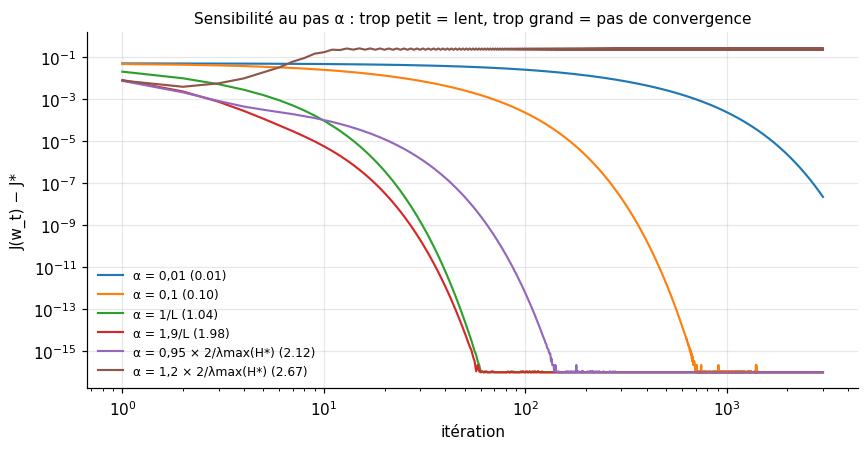

,α,J - J* après 100 itérations,après 3000,converge
pas,,,,
"0,01",0.010000,2.493188e-02,2.212987e-08,False
"0,1",0.100000,2.247498e-04,1.000000e-16,True
1/L,1.039728,1.000000e-16,1.000000e-16,True
"1,9/L",1.975484,1.000000e-16,1.000000e-16,True
"0,95 × 2/λmax(H*)",2.115031,5.851986e-13,1.000000e-16,True
"1,2 × 2/λmax(H*)",2.671618,2.220996e-01,2.220996e-01,False


In [6]:
p_opt = sigmoide(X @ w_gd + b_gd)
H = Xt.T @ (Xt * (p_opt * (1 - p_opt))[:, None]) / m + 2 * LAM * np.diag(np.r_[np.ones(d), 0.0])
LAMBDA_MAX_H = np.linalg.eigvalsh(H).max()
J_ETOILE = cout(w_gd, b_gd, X, y, LAM)
print(f"borne théorique 2/L = {2 / L_BORNE:.2f} | limite locale 2/λmax(H*) = {2 / LAMBDA_MAX_H:.2f}")

PAS = {"0,01": 0.01, "0,1": 0.1, "1/L": ALPHA, "1,9/L": 1.9 / L_BORNE,
       "0,95 × 2/λmax(H*)": 0.95 * 2 / LAMBDA_MAX_H, "1,2 × 2/λmax(H*)": 1.2 * 2 / LAMBDA_MAX_H}
fig, ax = plt.subplots(figsize=(8, 4.2))
lignes = []
for nom, a in PAS.items():
    _, _, h = descente(X, y, a, LAM, 3000)
    ecart = np.maximum(h - J_ETOILE, 1e-16)
    ax.plot(np.arange(1, len(h) + 1), ecart, label=f"α = {nom} ({a:.2f})", lw=1.4)
    lignes.append({"pas": nom, "α": a, "J - J* après 100 itérations": ecart[99], "après 3000": ecart[-1],
                   "converge": bool(ecart[-1] < 1e-8)})
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("itération"); ax.set_ylabel("J(w_t) − J*")
ax.set_title("Sensibilité au pas α : trop petit = lent, trop grand = pas de convergence", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "05_sensibilite_pas.png")
plt.show()
pd.DataFrame(lignes).set_index("pas")

### 6b. Le nombre d'itérations

Avec α = 1/L, on suit la log-loss d'entraînement et de validation au fil des itérations. Arrêter tôt revient à régulariser davantage : les poids partent de 0 et n'ont pas encore atteint le minimum.

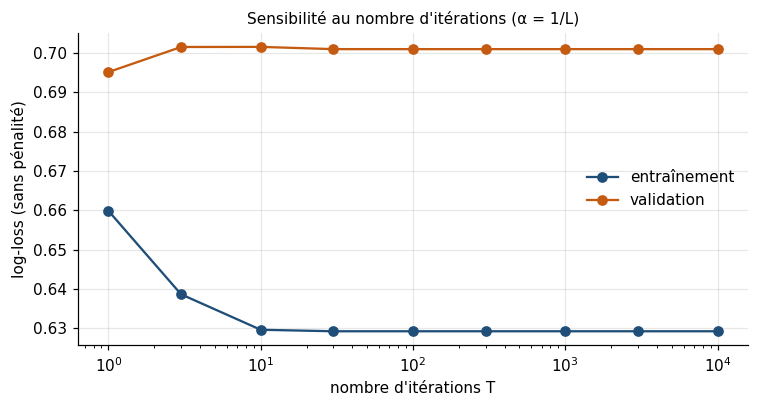

,log-loss entraînement,log-loss validation,‖w‖
itérations T,,,
1,0.6599,0.6951,0.1668
3,0.6387,0.7015,0.2834
10,0.6297,0.7015,0.3385
30,0.6293,0.7009,0.3422
100,0.6293,0.7009,0.3422
300,0.6293,0.7009,0.3422
1000,0.6293,0.7009,0.3422
3000,0.6293,0.7009,0.3422
10000,0.6293,0.7009,0.3422


In [7]:
POINTS = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000]
w, b, lignes = np.zeros(d), 0.0, []
fait = 0
for T in POINTS:
    w, b, _ = descente(X, y, ALPHA, LAM, T - fait, w=w, b=b)
    fait = T
    lignes.append({"itérations T": T, "log-loss entraînement": cout(w, b, X, y), "log-loss validation": cout(w, b, Xv, yv),
                   "‖w‖": np.linalg.norm(w)})
ITER = pd.DataFrame(lignes).set_index("itérations T")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ITER.index, ITER["log-loss entraînement"], marker="o", color="#1f4e79", label="entraînement")
ax.plot(ITER.index, ITER["log-loss validation"], marker="o", color="#c55a11", label="validation")
ax.set_xscale("log"); ax.set_xlabel("nombre d'itérations T"); ax.set_ylabel("log-loss (sans pénalité)")
ax.set_title("Sensibilité au nombre d'itérations (α = 1/L)", fontsize=10)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "05_sensibilite_iterations.png")
plt.show()
ITER.round(4)

### 6c. La force de régularisation λ

Pour chaque λ, on mesure la log-loss d'entraînement, la log-loss de validation croisée temporelle (les 4 folds du notebook 02, préparation réajustée dans chaque fold), la log-loss de validation et la norme des poids. C'est le compromis biais-variance de S3 : un λ trop petit colle au bruit, un λ trop grand ramène tout vers la constante.

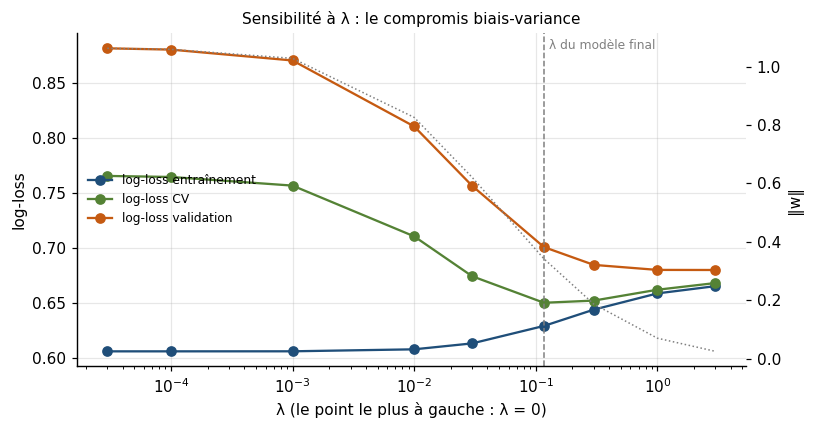

,log-loss entraînement,log-loss CV,log-loss validation,‖w‖
λ,,,,
0.000000,0.6062,0.7656,0.8817,1.0626
0.000100,0.6062,0.7647,0.8805,1.0590
0.001000,0.6062,0.7569,0.8706,1.0283
0.010000,0.6080,0.7107,0.8107,0.8262
0.030000,0.6134,0.6744,0.7566,0.6208
0.116802,0.6293,0.6503,0.7009,0.3422
0.300000,0.6441,0.6523,0.6848,0.1872
1.000000,0.6588,0.6622,0.6802,0.0705
3.000000,0.6655,0.6683,0.6801,0.0255


In [8]:
FOLDS = list(TimeSeriesSplit(n_splits=4, test_size=12).split(train))

def ajuster(Xa, ya, lam, T=4000):
    La = 0.25 * np.linalg.eigvalsh(np.c_[Xa, np.ones(len(Xa))].T @ np.c_[Xa, np.ones(len(Xa))] / len(Xa)).max() + 2 * lam
    w, b, _ = descente(Xa, ya, 1 / La, lam, T, suivi=set())
    return w, b

LAMBDAS = [0.0, 1e-4, 1e-3, 1e-2, 3e-2, LAM, 0.3, 1.0, 3.0]
lignes = []
for lam in LAMBDAS:
    pertes_cv = []
    for a, bb in FOLDS:
        prep = clone(PREP).fit(train[COLONNES].iloc[a])
        wf, bf = ajuster(prep.transform(train[COLONNES].iloc[a]), y[a], lam)
        pertes_cv.append(cout(wf, bf, prep.transform(train[COLONNES].iloc[bb]), y[bb]))
    w, b = ajuster(X, y, lam)
    lignes.append({"λ": lam, "log-loss entraînement": cout(w, b, X, y), "log-loss CV": np.mean(pertes_cv),
                   "log-loss validation": cout(w, b, Xv, yv), "‖w‖": np.linalg.norm(w)})
LAMB = pd.DataFrame(lignes).set_index("λ")

fig, ax1 = plt.subplots(figsize=(7.5, 4))
x = [max(l, 3e-5) for l in LAMBDAS]
for col, coul in [("log-loss entraînement", "#1f4e79"), ("log-loss CV", "#548235"), ("log-loss validation", "#c55a11")]:
    ax1.plot(x, LAMB[col], marker="o", color=coul, label=col)
ax1.axvline(LAM, color="grey", ls="--", lw=1)
ax1.text(LAM * 1.1, ax1.get_ylim()[1] - 0.005, "λ du modèle final", color="grey", fontsize=8, va="top")
ax1.set_xscale("log"); ax1.set_xlabel("λ (le point le plus à gauche : λ = 0)"); ax1.set_ylabel("log-loss")
ax2 = ax1.twinx()
ax2.plot(x, LAMB["‖w‖"], color="grey", lw=1, ls=":", label="‖w‖ (axe de droite)")
ax2.set_ylabel("‖w‖"); ax2.grid(False)
ax1.legend(frameon=False, fontsize=8, loc="center left")
ax1.set_title("Sensibilité à λ : le compromis biais-variance", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "05_sensibilite_lambda.png")
plt.show()
LAMB.round(4)

### 6d. Le point de départ

J<sub>λ</sub> est strictement convexe : la descente doit trouver le même minimum quel que soit le point de départ. On le vérifie avec trois départs.

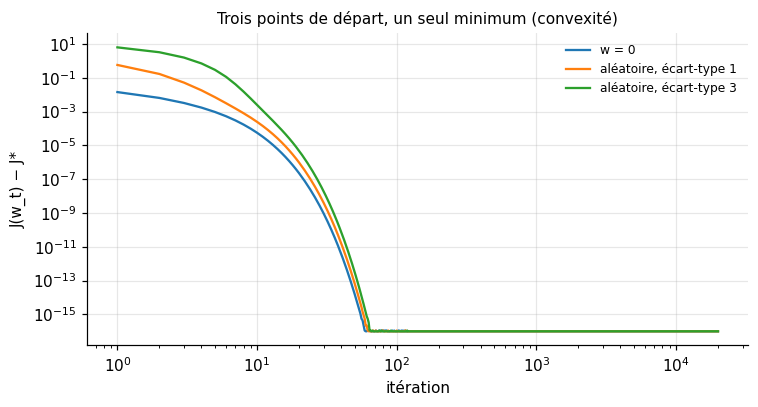

,J de départ,écart max à w*
départ,,
w = 0,0.693147,1.387779e-17
"aléatoire, écart-type 1",2.295613,3.512815e-17
"aléatoire, écart-type 3",12.410347,3.252607e-17


In [9]:
departs = {"w = 0": np.zeros(d), "aléatoire, écart-type 1": rng.normal(0, 1, d), "aléatoire, écart-type 3": rng.normal(0, 3, d)}
fig, ax = plt.subplots(figsize=(7, 3.8))
lignes = []
for nom, w_init in departs.items():
    w, b, h = descente(X, y, ALPHA, LAM, 20000, w=w_init, b=float(rng.normal()))
    ax.plot(np.arange(1, len(h) + 1), np.maximum(h - J_ETOILE, 1e-16), label=nom)
    lignes.append({"départ": nom, "J de départ": cout(w_init, 0.0, X, y, LAM), "écart max à w*": np.abs(w - w_gd).max()})
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("itération"); ax.set_ylabel("J(w_t) − J*")
ax.set_title("Trois points de départ, un seul minimum (convexité)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "05_sensibilite_depart.png")
plt.show()
pd.DataFrame(lignes).set_index("départ")

## 7. Option L2 : pourquoi pas une régression sur le rendement ?

Avec les mêmes 12 variables, on résout les équations normales X̃<sup>⊤</sup>X̃β = X̃<sup>⊤</sup>r (L2) pour prédire le rendement du mois suivant, puis on mesure le R².

In [10]:
r_tr, r_va = train["target_rn_next"].to_numpy(), valid["target_rn_next"].to_numpy()
beta = np.linalg.solve(Xt.T @ Xt, Xt.T @ r_tr)
ols = LinearRegression().fit(X, r_tr)
r2 = lambda r, rhat: 1 - ((r - rhat) ** 2).sum() / ((r - r.mean()) ** 2).sum()
print(f"équations normales vs scikit-learn : écart max {np.abs(beta - np.r_[ols.coef_, ols.intercept_]).max():.1e}")
print(f"R² entraînement : {r2(r_tr, Xt @ beta):.3f} | R² validation : {r2(r_va, np.c_[Xv, np.ones(len(Xv))] @ beta):.3f}")

équations normales vs scikit-learn : écart max 7.0e-17
R² entraînement : 0.120 | R² validation : -1.774


## 8. Ce qu'on retient

- **Le gradient est juste.** Le gradient analytique et les différences finies s'accordent à 1,3 × 10⁻⁹ près (écart relatif).
- **La descente codée à la main retrouve scikit-learn.** Après 20 000 itérations avec α = 1/L, les 13 paramètres coïncident à 5 × 10⁻⁶ près avec `lbfgs`, et à 7 × 10⁻⁵ près avec le modèle final entraîné par `saga`. La norme du gradient au point trouvé vaut 10⁻¹⁷ : la condition d'optimalité ∇J<sub>λ</sub> = 0 est vérifiée.
- **Le prior a un sens concret.** Le λ = 0,117 choisi par Optuna correspond à un écart-type a priori τ = 0,17 par poids standardisé.
- **Pas α (L1, L8).**
    - La borne théorique vaut 2/L = 2,08 ; la vraie limite locale, calculée avec la hessienne au minimum, vaut 2/λ<sub>max</sub>(H\*) = 2,23. La borne est prudente, parce que p(1 − p) reste sous ¼.
    - Trop petit (α = 0,01), la descente est lente : encore 2 × 10⁻⁸ d'écart à J\* après 3 000 itérations.
    - De α = 0,1 à 0,95 × 2,23, elle converge, d'autant plus vite que α est grand.
    - À 1,2 × 2,23, elle ne converge plus : l'écart à J\* reste bloqué à 0,22.
- **Itérations.** Avec α = 1/L, la descente converge en une trentaine d'itérations. La log-loss de validation est la plus basse dès la première itération (0,695 contre 0,701 à convergence) : arrêter tôt régularise, ce qui confirme qu'il y a peu de signal stable.
- **λ et le compromis biais-variance (S3).**
    - Sans pénalité, la log-loss d'entraînement est la plus basse (0,606), mais celle de validation croisée monte à 0,766 et celle de validation à 0,882 : c'est du sur-apprentissage.
    - La validation croisée est minimale au λ choisi par Optuna (0,650), ce qui confirme le réglage du notebook 02.
    - Sur la validation 2022-2023, c'est le plus grand λ testé qui gagne (0,680), presque la constante : le même constat qu'au notebook 03.
- **Point de départ.** Trois départs très différents (J de départ entre 0,69 et 12,4) mènent au même minimum, à 10⁻¹⁷ près. C'est la stricte convexité de J<sub>λ</sub>, observée en pratique.
- **Option L2.** Les équations normales résolues à la main retrouvent scikit-learn à 10⁻¹⁶ près. Le R² vaut 0,12 sur l'entraînement mais **−1,77 sur la validation** : prédire le montant du rendement est hors de portée, ce qui justifie la classification.

**À reprendre dans l'annexe LaTeX (3 à 5 pages).** Les dérivations des sections 1 à 4, le tableau de comparaison de la section 5 et les quatre figures de sensibilité (`figures/05_sensibilite_*.png`).
